In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import warnings
warnings.filterwarnings("ignore")

In [2]:
df = pd.read_csv("/content/AmesHousing.csv")

df.head()

,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,1,526301100,20,RL,141.0,31770,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,NaN,0,5,2010,WD,Normal,215000
1,2,526350040,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,...,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal,105000
2,3,526351010,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal,172000
3,4,526353030,20,RL,93.0,11160,Pave,NaN,Reg,Lvl,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,244000
4,5,527105010,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,...,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal,189900


In [4]:
print("Dataset Shape:", df.shape)

df.info()

df.describe()

df.isnull().sum()

Dataset Shape: (2930, 82)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2930 entries, 0 to 2929
Data columns (total 82 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Order            2930 non-null   int64  
 1   PID              2930 non-null   int64  
 2   MS SubClass      2930 non-null   int64  
 3   MS Zoning        2930 non-null   object 
 4   Lot Frontage     2440 non-null   float64
 5   Lot Area         2930 non-null   int64  
 6   Street           2930 non-null   object 
 7   Alley            198 non-null    object 
 8   Lot Shape        2930 non-null   object 
 9   Land Contour     2930 non-null   object 
 10  Utilities        2930 non-null   object 
 11  Lot Config       2930 non-null   object 
 12  Land Slope       2930 non-null   object 
 13  Neighborhood     2930 non-null   object 
 14  Condition 1      2930 non-null   object 
 15  Condition 2      2930 non-null   object 
 16  Bldg Type        2930 non-null   o

,0
Order,0
PID,0
MS SubClass,0
MS Zoning,0
Lot Frontage,490
...,...
Mo Sold,0
Yr Sold,0
Sale Type,0
Sale Condition,0


In [5]:
df = df.drop_duplicates()

In [6]:
df = df.dropna()

In [7]:
print(df.isnull().sum())
print(df.shape)

Order             0
PID               0
MS SubClass       0
MS Zoning         0
Lot Frontage      0
                 ..
Mo Sold           0
Yr Sold           0
Sale Type         0
Sale Condition    0
SalePrice         0
Length: 82, dtype: int64
(0, 82)


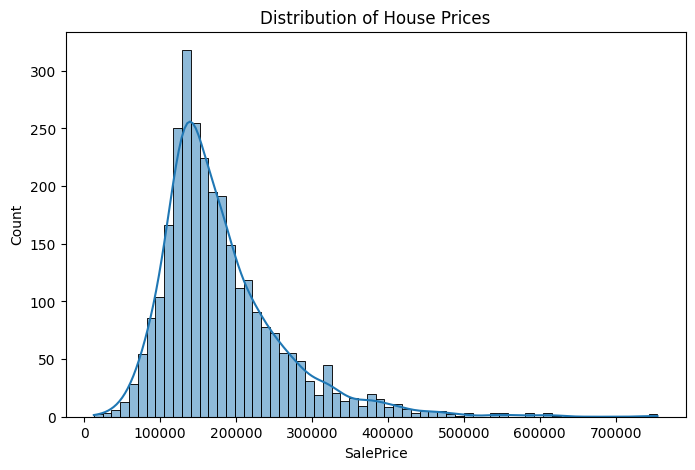

In [10]:
# Reload the dataset to recover rows deleted by the previous dropna() call
df = pd.read_csv("/content/AmesHousing.csv")

# Plot the correct target column 'SalePrice'
plt.figure(figsize=(8,5))
sns.histplot(df["SalePrice"], kde=True)
plt.title("Distribution of House Prices")
plt.show()

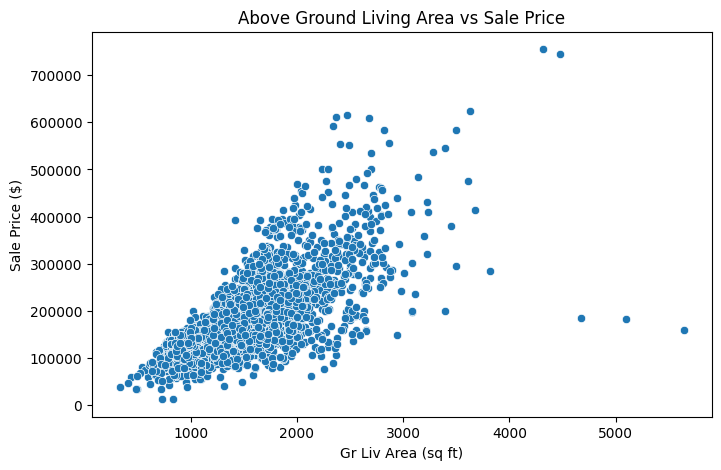

In [12]:
plt.figure(figsize=(8,5))
sns.scatterplot(x=df["Gr Liv Area"], y=df["SalePrice"])
plt.title("Above Ground Living Area vs Sale Price")
plt.xlabel("Gr Liv Area (sq ft)")
plt.ylabel("Sale Price ($)")
plt.show()

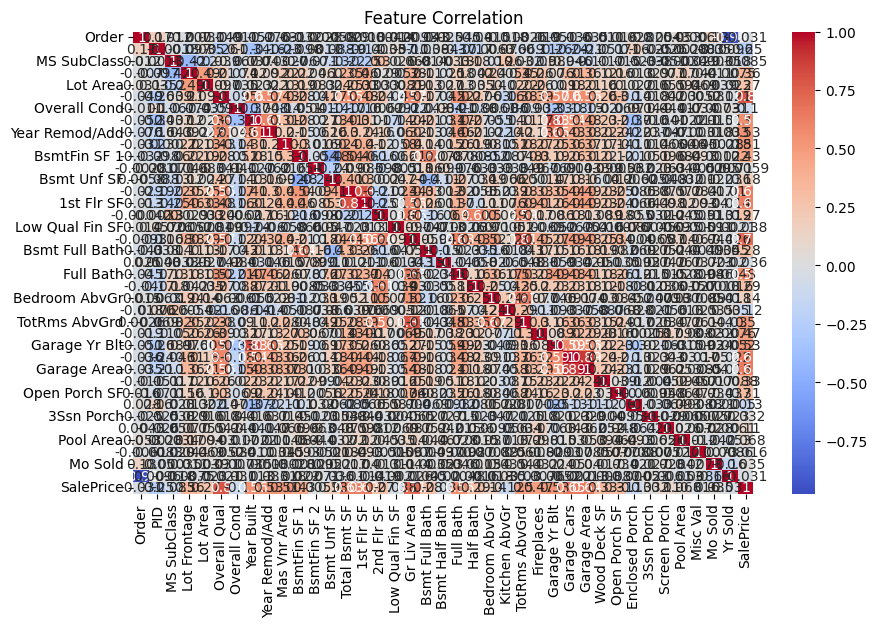

In [13]:
plt.figure(figsize=(10,6))
sns.heatmap(df.select_dtypes(include="number").corr(),
            annot=True, cmap="coolwarm")
plt.title("Feature Correlation")
plt.show()

In [15]:
X = df.drop("SalePrice", axis=1)
y = df["SalePrice"]

In [16]:
X = pd.get_dummies(X, drop_first=True)

In [17]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [19]:
# LinearRegression does not accept missing values. Let's fill NaNs using simple imputation.
X_train_imputed = X_train.fillna(X_train.median())
X_test_imputed = X_test.fillna(X_train.median()) # Avoid data leakage by using train set median

lr = LinearRegression()
lr.fit(X_train_imputed, y_train)

lr_predictions = lr.predict(X_test_imputed)

In [20]:
rf = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

rf.fit(X_train, y_train)

rf_predictions = rf.predict(X_test)

In [21]:
def evaluate_model(actual, predicted, model_name):

    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    r2 = r2_score(actual, predicted)

    print("Model:", model_name)
    print("MAE:", mae)
    print("RMSE:", rmse)
    print("R2 Score:", r2)
    print("----------------------")

evaluate_model(y_test, lr_predictions, "Linear Regression")

evaluate_model(y_test, rf_predictions, "Random Forest")

Model: Linear Regression
MAE: 15969.281126566908
RMSE: 28882.191243360925
R2 Score: 0.8959555991174939
----------------------
Model: Random Forest
MAE: 15785.065017064846
RMSE: 26194.069651392514
R2 Score: 0.914421554967328
----------------------


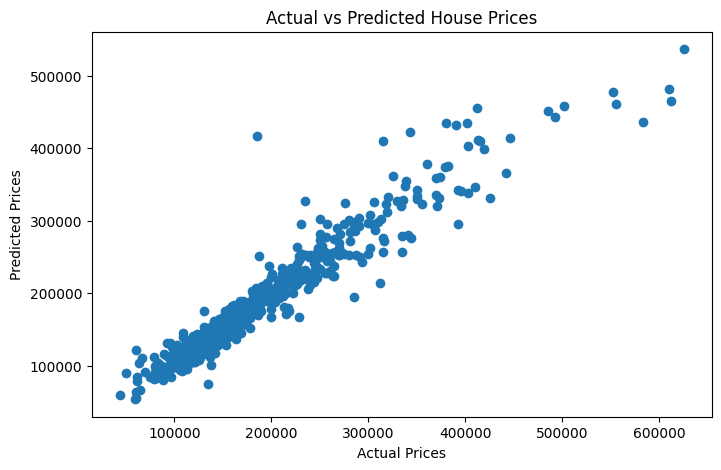

In [22]:
plt.figure(figsize=(8,5))

plt.scatter(y_test, rf_predictions)

plt.xlabel("Actual Prices")
plt.ylabel("Predicted Prices")

plt.title("Actual vs Predicted House Prices")

plt.show()

In [23]:
import joblib

joblib.dump(rf, "house_price_model.pkl")

['house_price_model.pkl']